In [2]:
import sys
sys.path.append('..')  # to import from parent directory


import matplotlib as mpl
mpl.rcParams['legend.markerscale'] = 1.5
mpl.rcParams['pdf.fonttype'] = 42
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc
from statannotations.Annotator import Annotator
import os
import pandas as pd
import numpy as np
from utils.mypalette import day_palette


global_annotations = pd.read_csv('../data/crop16_EF_2405.csv')
global_annotations['file_name'] = global_annotations['img_code'].apply(lambda x: os.path.basename(x).split('.')[0])

results_df = pd.read_csv('./SUPP_2_batch_exclusion_results/loo_predictions.csv')


/tmp/ipykernel_1036572/1262912546.py:18: DtypeWarning: Columns (17) have mixed types. Specify dtype option on import or set low_memory=False.
  global_annotations = pd.read_csv('../data/crop16_EF_2405.csv')


In [3]:
# Count the number of samples per batch, classifier, and true label
if "task" in results_df.columns:
    results_df.rename(columns={"task": "classifier"}, inplace=True)
balance_check = results_df.groupby(['classifier', 'test_batch', 'true']).size().unstack(fill_value=0)
print(balance_check)

# Optional: check if all numbers are identical across classes for each batch/classifier
for clf in results_df['classifier'].unique():
    clf_df = balance_check.loc[clf]
    if clf_df.nunique().max() == 1:
        print(f"{clf}: perfectly balanced across batches and classes")
    else:
        print(f"{clf}: NOT balanced! Counts per batch/class:")
        print(clf_df)

seed_counts = results_df.groupby(['classifier', 'test_batch', 'ds_seed', 'mlp_seed']).size()
seed_counts_unstack = seed_counts.unstack(level=['ds_seed', 'mlp_seed'], fill_value=0)
print(seed_counts_unstack)

true                   A1 high  A1 low    als  control  untreated
classifier test_batch                                            
ALS        E1                0       0  57100    57100          0
           E2                0       0  57100    57100          0
           E3                0       0  57100    57100          0
           E4                0       0  57100    57100          0
TIC high   E1            57100       0      0        0      57100
           E2            57100       0      0        0      57100
           E3            57100       0      0        0      57100
           E4            57100       0      0        0      57100
TIC low    E1                0   57100      0        0      57100
           E4                0   57100      0        0      57100
ALS: perfectly balanced across batches and classes
TIC high: perfectly balanced across batches and classes
TIC low: perfectly balanced across batches and classes
ds_seed                   0                   

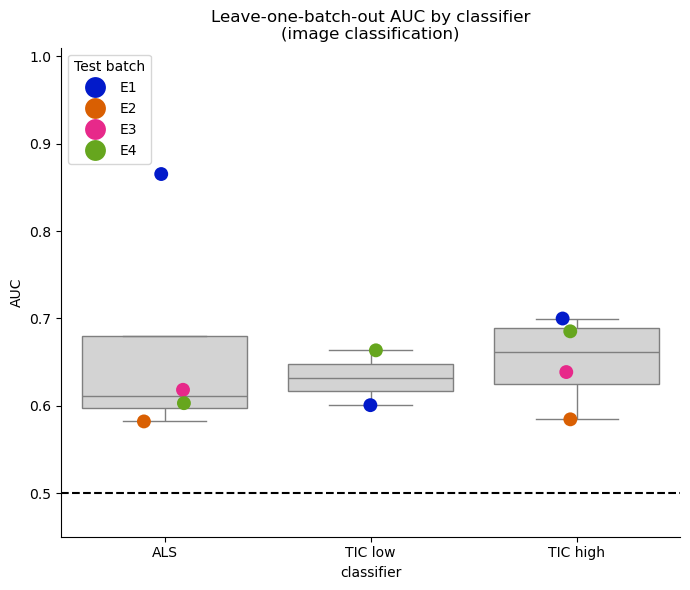

In [13]:
# Compute AUC per classifier and per batch (one point per batch)
classifiers_of_interest = ['ALS', 'TIC low', 'TIC high']
# Mapping to positive label names in the annotations (adjust if your labels differ)
pos_label_map = {'ALS': 'als', 'TIC low': 'A1 low', 'TIC high': 'A1 high'}

def _flatten_series(series):
    # Flatten elements that may be lists/arrays or stringified lists
    out = []
    for v in series:
        if isinstance(v, (list, tuple, np.ndarray)):
            out.extend(np.array(v).ravel().tolist())
        else:
            if isinstance(v, str) and v.startswith('[') and v.endswith(']'):
                try:
                    parsed = eval(v)
                    out.extend(np.array(parsed).ravel().tolist())
                except Exception:
                    out.append(v)
            else:
                out.append(v)
    return np.array(out)

auc_values = []
batches = np.unique(results_df['test_batch'].values)
for clf in classifiers_of_interest:
    for batch in batches:
        temp = results_df[(results_df['classifier'] == clf) & (results_df['test_batch'] == batch)]
        if temp.empty:
            continue
        # Flatten true labels and predicted probabilities
        y_true = _flatten_series(temp['true'])
        y_pred = _flatten_series(temp['pred_prob'])
        # Ensure arrays are 1D and same length
        if len(y_true) == 0 or len(y_pred) == 0 or len(y_true) != len(y_pred):
            # skip problematic entries
            continue
        # Determine pos_label for this classifier if available
        pos_label = pos_label_map.get(clf, None)
        try:
            if pos_label is not None:
                fpr, tpr, _ = roc_curve(y_true, y_pred, pos_label=pos_label)
            else:
                fpr, tpr, _ = roc_curve(y_true, y_pred)
            auc_ = auc(fpr, tpr)
        except Exception:
            # fallback: try converting labels to 0/1
            try:
                y_true_bin = np.array([1 if str(x).lower() == str(pos_label).lower() else 0 for x in y_true]) if pos_label is not None else np.array(y_true).astype(float)
                fpr, tpr, _ = roc_curve(y_true_bin, y_pred)
                auc_ = auc(fpr, tpr)
            except Exception:
                continue
        auc_values.append({'classifier': clf, 'batch': batch, 'auc': auc_})

# Convert to DataFrame
auc_df = pd.DataFrame(auc_values)

# Plot: classifier on x-axis, AUC on y-axis, one point per batch (colored by batch)
fig, ax = plt.subplots(figsize=(7, 6))
# light box to show distribution (if multiple points per classifier exist)
sns.boxplot(x='classifier', y='auc', data=auc_df, ax=ax, color='lightgray', fliersize=0)
sns.stripplot(x='classifier', y='auc', data=auc_df, ax=ax, hue='batch', dodge=False, jitter=0.1, marker='o', size=10, palette=day_palette)
ax.set_ylabel('AUC')
ax.set_ylim([0.45, 1.01])
ax.set_title('Leave-one-batch-out AUC by classifier\n(image classification)')
ax.axhline(0.5, color='k', linestyle='--')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
# Place legend outside
ax.legend(title='Test batch', loc='upper left')
plt.tight_layout()
plt.savefig('classifiers_per_batch_auc.pdf')
plt.show()